# 03 - Can a wearable IMU suit replace the instrumented treadmill?

**Question.** Instrumented treadmills are expensive, fixed installations. A body-worn IMU suit is portable.
This notebook measures how closely the IMU reproduces the force-plate reference on four levels:

1. gait event timing (heel strike and toe-off);
2. the spatiotemporal parameters a clinician would report;
3. walking speed, which the suit estimates on its own;
4. ground reaction forces, which an IMU cannot measure directly and must be predicted ("virtual force plate").

**Validation design.** The only tuned setting in the IMU event detector (the foot-speed threshold) was
chosen on ten development participants (S4 to S13). All agreement statistics below are computed on the
remaining participants, excluding the pilot sessions (S1 to S3), and only on trials whose force-plate and
IMU clocks are aligned within 0.1 s (notebook 01). Force prediction models are scored with participants
held out as whole groups.

In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed

from mgait import config as C, features as F, gait as G, models as Mo, plotting as P, stats as S

P.use_style()
pd.set_option("display.width", 200, "display.max_columns", 30, "display.precision", 3)
sync = pd.read_parquet(C.TABLES / "sync.parquet")
ev = pd.read_parquet(C.CACHE / "event_errors.parquet")
T = pd.read_parquet(C.TABLES / "trial_features.parquet")
aligned = sync.loc[sync["final_lag_s"].abs() <= 0.1, ["subject", "speed"]]
heldout = aligned[~aligned["subject"].isin(C.DEV_SUBJECTS + C.PILOT_SUBJECTS)]
print(f"Held-out evaluation set: {len(heldout)} trials from {heldout.subject.nunique()} participants")

Held-out evaluation set: 129 trials from 45 participants


## 1. Calibration on development participants

The detector marks a foot as in contact while its horizontal speed is below a fraction of that trial's
95th-percentile foot speed. The fraction was swept on the development participants only.

mae          bias        detect      
kind     hs     to     hs     to     hs    to
fr                                           
0.05  147.9  132.7  147.9 -132.6   92.9  91.6
0.10   99.4   87.8   95.9  -87.1   99.6  99.7
0.15   56.6   65.7   48.0  -63.5  100.0  99.9
0.20   33.5   50.3   18.3  -45.6   99.9  99.8
0.25   27.4   39.8    3.5  -29.1   99.9  99.8
0.30   27.1   33.9   -6.8  -12.2   99.9  99.8
0.35   28.9   32.8  -15.6    6.4   99.8  99.7
0.40   33.0   40.3  -23.7   28.8   99.7  99.7
0.50   43.3   85.6  -38.4   84.8   99.6  99.6

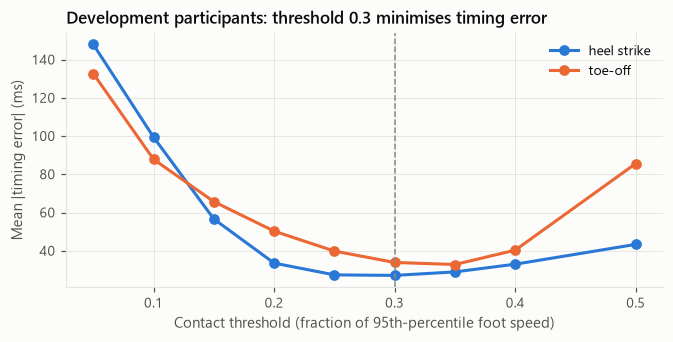

In [2]:
def sweep(s, v, fr):
    fp = G.fp_process(s, v, swap=s == "S5")
    im = G.imu_process(s, v, fr)
    if fp is None or not fp.usable or im is None:
        return None
    m = G.match_events(fp.events, im.events, lag=0.0)
    return m.assign(fr=fr, subject=s, speed=v)

dev_trials = aligned[aligned["subject"].isin(C.DEV_SUBJECTS)]
res = Parallel(n_jobs=-1)(delayed(sweep)(r.subject, r.speed, fr) for r in dev_trials.itertuples()
                          for fr in (0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.5))
cal = pd.concat([r for r in res if r is not None])
cs = cal.groupby(["fr", "kind"])["err"].agg(mae=lambda e: 1e3 * e.abs().mean(), bias=lambda e: 1e3 * e.mean(),
                                            detect=lambda e: 100 * e.notna().mean()).unstack("kind")
display(cs.round(1))
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(cs.index, cs[("mae", "hs")], marker="o", color=P.CAT[0], label="heel strike")
ax.plot(cs.index, cs[("mae", "to")], marker="o", color=P.CAT[1], label="toe-off")
ax.axvline(C.IMU_THR_FRAC, color=P.MUTED, ls="--", lw=1)
ax.set_xlabel("Contact threshold (fraction of 95th-percentile foot speed)")
ax.set_ylabel("Mean |timing error| (ms)")
ax.set_title(f"Development participants: threshold {C.IMU_THR_FRAC} minimises timing error")
ax.legend()
P.save(fig, "03_calibration")
plt.show()

## 2. Event timing on held-out participants

,reference events,detected (%),bias (ms),SD (ms),95% limits (ms),median |error| (ms),within-trial SD (ms),SD of trial offsets (ms)
event,,,,,,,,
Heel strike,12096,99.0,-17.7,49.1,-114 to 79,31.7,28.0,40.8
Toe-off,12096,99.0,-25.5,48.9,-121 to 70,38.3,25.2,42.2


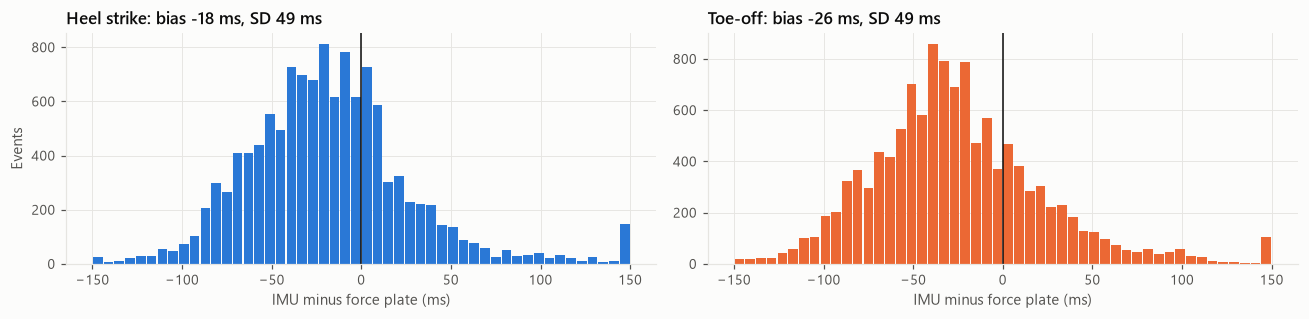

In [3]:
e = ev.merge(heldout, on=["subject", "speed"])
summary = []
for kind, name in (("hs", "Heel strike"), ("to", "Toe-off")):
    sub = e[e["kind"] == kind]
    x = 1e3 * sub["err"]
    ba = S.bland_altman(np.zeros(x.notna().sum()), x.dropna().to_numpy())
    # detector precision: spread after removing each trial's own mean offset (residual clock offset)
    within = (x - x.groupby([sub["subject"], sub["speed"]]).transform("mean")).dropna()
    offs = x.groupby([sub["subject"], sub["speed"]]).mean()
    summary.append({"event": name, "reference events": len(x), "detected (%)": 100 * x.notna().mean(),
                    "bias (ms)": ba["bias"], "SD (ms)": ba["sd"], "95% limits (ms)": f"{ba['loa_lo']:.0f} to {ba['loa_hi']:.0f}",
                    "median |error| (ms)": x.abs().median(),
                    "within-trial SD (ms)": within.std(), "SD of trial offsets (ms)": offs.std()})
ev_sum = pd.DataFrame(summary).set_index("event")
ev_sum.to_csv(C.TABLES / "imu_event_agreement.csv")
display(ev_sum.round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 3))
for ax, kind, name, col in zip(axes, ("hs", "to"), ("Heel strike", "Toe-off"), (P.CAT[0], P.CAT[1])):
    x = 1e3 * e.loc[e["kind"] == kind, "err"].dropna()
    ax.hist(x.clip(-150, 150), bins=np.arange(-150, 152, 6), color=col, rwidth=0.9)
    ax.axvline(0, color=P.INK, lw=1)
    ax.set_xlabel("IMU minus force plate (ms)")
    ax.set_title(f"{name}: bias {x.mean():.0f} ms, SD {x.std():.0f} ms")
axes[0].set_ylabel("Events")
fig.tight_layout()
P.save(fig, "03_event_errors")
plt.show()

The IMU detects 99 % of force-plate events. Heel strikes are reported 18 ms early and toe-offs 26 ms
early on average. The total spread (SD about 49 ms) has two parts: the detector's own jitter within a
trial, and a constant offset per trial that reflects residual clock misalignment between the two systems
(they were started separately). The within-trial SD is the better measure of detector precision; one IMU
frame is 16.7 ms.

## 3. Spatiotemporal parameters

Per-trial medians from each system, on the same held-out aligned trials.

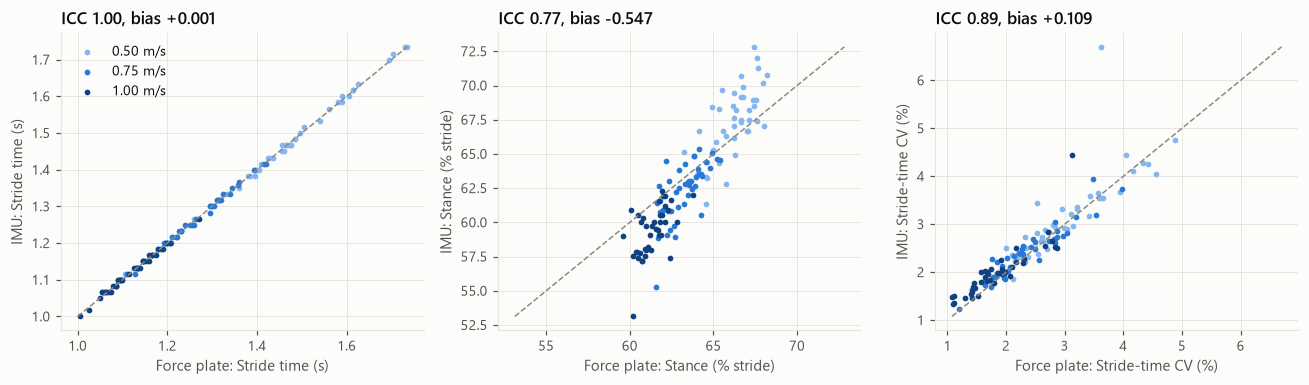

,n trials,force plate mean,IMU mean,bias,95% limits,"ICC(A,1)"
parameter,,,,,,
Stride time (s),128,1.283,1.284,0.001,-0.011 to 0.013,0.999
Stance (% stride),128,63.644,63.097,-0.547,-4.699 to 3.605,0.773
Stride-time CV (%),128,2.417,2.526,0.109,-0.592 to 0.810,0.894


In [4]:
H = T.merge(heldout, on=["subject", "speed"])
pairs = [("stride_time", "Stride time (s)"), ("stance_pct", "Stance (% stride)"), ("stride_cv", "Stride-time CV (%)")]
rows = []
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, (f, lab) in zip(axes, pairs):
    ref, tst = H[f"fp_{f}"].to_numpy(), H[f"imu_{f}"].to_numpy()
    okm = np.isfinite(ref) & np.isfinite(tst)
    ba = S.bland_altman(ref[okm], tst[okm])
    icc = S.icc_a1(ref[okm], tst[okm])
    rows.append({"parameter": lab, "n trials": ba["n"], "force plate mean": ref[okm].mean(), "IMU mean": tst[okm].mean(),
                 "bias": ba["bias"], "95% limits": f"{ba['loa_lo']:.3f} to {ba['loa_hi']:.3f}", "ICC(A,1)": icc})
    for s in C.SPEEDS:
        m = (H["speed"] == s).to_numpy() & okm
        ax.scatter(ref[m], tst[m], s=14, color=P.SPEED_COLORS[s], label=P.SPEED_LABEL[s])
    lo, hi = np.nanmin([ref[okm].min(), tst[okm].min()]), np.nanmax([ref[okm].max(), tst[okm].max()])
    ax.plot([lo, hi], [lo, hi], color=P.MUTED, ls="--", lw=1)
    ax.set_xlabel(f"Force plate: {lab}"); ax.set_ylabel(f"IMU: {lab}")
    ax.set_title(f"ICC {icc:.2f}, bias {ba['bias']:+.3f}")
axes[0].legend()
fig.tight_layout()
P.save(fig, "03_spatiotemporal_agreement")
plt.show()
st_agree = pd.DataFrame(rows).set_index("parameter")
st_agree.to_csv(C.TABLES / "imu_spatiotemporal_agreement.csv")
display(st_agree.round(3))

Stride time is reproduced almost exactly: both systems count the same strides, so per-trial medians agree
to within a few milliseconds. Stance percentage carries the small heel-strike and toe-off biases and is
reproduced with good but not interchangeable agreement. Stride-time variability is the most demanding
parameter, because frame-level jitter in event timing inflates the IMU estimate directly; it agrees less
well and should be reported from the IMU only with that caveat.

## 4. Walking speed estimated by the suit

The suit has no knowledge of the belt speed. MVN integrates treadmill walking as forward progression,
so average pelvis speed is an independent speed estimate.

,trials,mean_estimate,bias,mae,mape,within_10pct
speed,,,,,,
0.5,58,0.493,-0.007,0.021,4.244,91.379
0.75,56,0.728,-0.022,0.031,4.153,92.857
1,55,0.965,-0.035,0.044,4.422,92.727


Overall: mean absolute error 0.032 m/s (4.3 %), 92 % of trials within 10 %


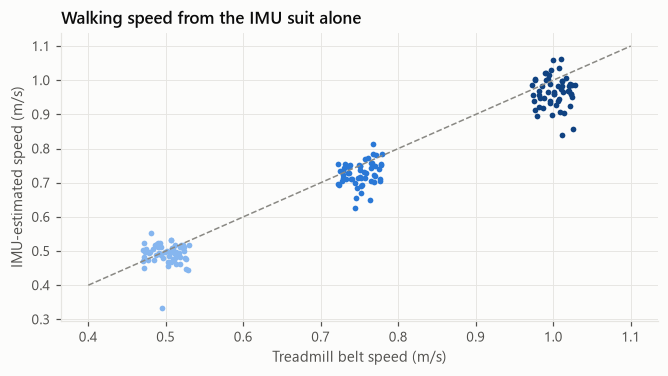

In [5]:
sp = T.dropna(subset=["imu_speed_est"]).copy()
sp["err"] = sp["imu_speed_est"] - sp["speed_ms"]
sp["pct"] = 100 * sp["err"] / sp["speed_ms"]
tab = sp.groupby("speed").agg(trials=("err", "size"), mean_estimate=("imu_speed_est", "mean"),
                              bias=("err", "mean"), mae=("err", lambda x: x.abs().mean()),
                              mape=("pct", lambda x: x.abs().mean()), within_10pct=("pct", lambda x: 100 * (x.abs() <= 10).mean()))
tab.to_csv(C.TABLES / "imu_speed_estimate.csv")
display(tab.round(3))
print(f"Overall: mean absolute error {sp['err'].abs().mean():.3f} m/s ({sp['pct'].abs().mean():.1f} %), "
      f"{(sp['pct'].abs() <= 10).mean() * 100:.0f} % of trials within 10 %")
fig, ax = plt.subplots(figsize=(7, 3.4))
for i, s in enumerate(C.SPEEDS):
    y = sp.loc[sp.speed == s, "imu_speed_est"]
    xj = C.SPEED_MS[s] + np.random.default_rng(i).uniform(-0.03, 0.03, len(y))
    ax.scatter(xj, y, s=14, color=P.SPEED_COLORS[s])
ax.plot([0.4, 1.1], [0.4, 1.1], color=P.MUTED, ls="--", lw=1)
ax.set_xlabel("Treadmill belt speed (m/s)"); ax.set_ylabel("IMU-estimated speed (m/s)")
ax.set_title("Walking speed from the IMU suit alone")
P.save(fig, "03_speed_estimate")
plt.show()

## 5. Joint kinematics across speed

Sagittal joint angles over the stride (IMU heel strike to heel strike), averaged within participant first.

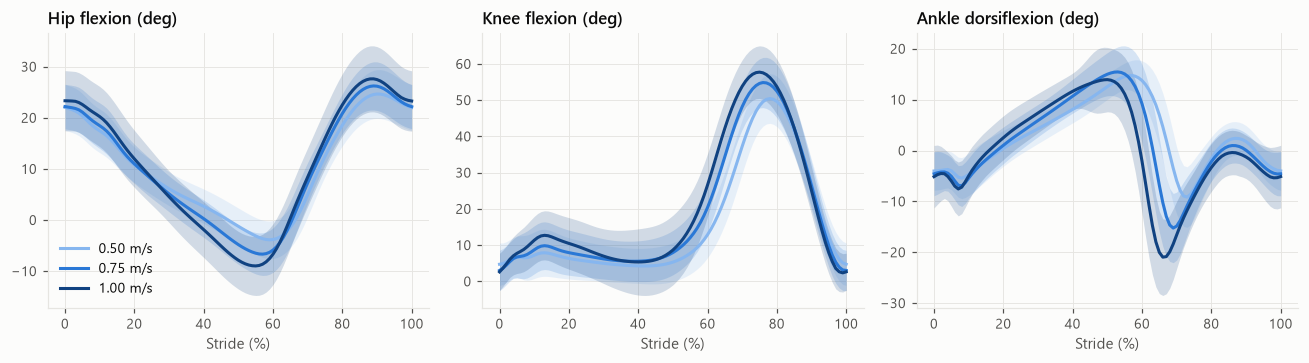

,n_subjects,mean_0.5,mean_1.0,per_0.5ms,ci_lo,ci_hi,std_effect,p_holm
feature,,,,,,,,
imu_hip_rom,58,30.025,37.392,7.235,6.219,8.250,1.190,1.759e-43
imu_hip_flex_max,58,25.286,28.025,2.608,1.307,3.908,0.488,1.697e-04
imu_hip_ext_max,58,4.750,9.505,4.773,3.725,5.821,0.959,2.202e-18
imu_knee_flex_swing,58,51.764,58.648,6.848,6.061,7.635,0.996,2.258e-64
imu_knee_flex_stance,58,9.759,13.986,4.411,3.433,5.388,0.684,3.731e-18
imu_knee_rom,58,51.420,59.433,7.911,6.758,9.064,1.216,1.872e-40
imu_ankle_rom,58,29.565,40.481,10.649,10.002,11.295,1.453,9.664e-228
imu_ankle_plantar_max,58,13.376,24.661,11.035,10.098,11.972,1.445,5.547e-117
imu_ankle_dorsi_max,58,16.200,15.653,-0.544,-1.198,0.111,-0.155,1.033e-01


In [6]:
imu = pd.read_parquet(C.CACHE / "imu_strides.parquet")
ic = dict(np.load(C.CACHE / "imu_curves.npz"))
okm = imu["qc_ok"].to_numpy()
x = np.arange(101)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, k, lab in zip(axes, ("hip_flex", "knee_flex", "ankle_dorsi"), ("Hip flexion (deg)", "Knee flexion (deg)", "Ankle dorsiflexion (deg)")):
    X = pd.DataFrame(ic[k][okm]); X["subject"], X["speed"] = imu.loc[okm, "subject"].values, imu.loc[okm, "speed"].values
    sm = X.groupby(["subject", "speed"]).mean()
    for s in C.SPEEDS:
        Mx = sm.xs(s, level="speed").to_numpy()
        P.band(ax, x, Mx.mean(0), Mx.std(0), P.SPEED_COLORS[s], P.SPEED_LABEL[s])
    ax.set_title(lab); ax.set_xlabel("Stride (%)")
axes[0].legend()
fig.tight_layout()
P.save(fig, "03_kinematics")
plt.show()

imu_feats = ["imu_hip_rom", "imu_hip_flex_max", "imu_hip_ext_max", "imu_knee_flex_swing", "imu_knee_flex_stance",
             "imu_knee_rom", "imu_ankle_rom", "imu_ankle_plantar_max", "imu_ankle_dorsi_max", "imu_hip_abd_rom"]
keff = S.speed_effects(T, imu_feats)
keff.to_csv(C.TABLES / "imu_speed_effects.csv", index=False)
display(keff.set_index("feature")[["n_subjects", "mean_0.5", "mean_1.0", "per_0.5ms", "ci_lo", "ci_hi", "std_effect", "p_holm"]])

## 6. A virtual force plate

Can IMU kinematics predict the ground reaction forces that only the force plates measure? Two levels are
tested, both with participants held out as whole groups (10-fold group cross-validation):

* **Trial level:** the force-plate summary features of notebook 02, predicted from IMU summary features plus
  the IMU's own speed estimate. Baselines: the training-set mean, and a model using the IMU speed estimate
  alone (because speed explains much of the loading change).
* **Stride level:** the full stance-phase vertical and anterior-posterior force waveforms of each stride,
  predicted from the same stride's IMU joint-angle curves (strides matched by heel-strike time, aligned
  trials only). Baseline: the mean waveform of the training participants at the same speed.

In [7]:
targets = ["fp_stance_pct", "fp_double_support_pct", "fp_fz_peak1", "fp_fz_valley", "fp_fz_peak2", "fp_loading_rate",
           "fp_fy_brake_peak", "fp_fy_prop_peak", "fp_fx_medial_peak"]
inputs = [c for c in T.columns if c.startswith("imu_") and c not in ("imu_n_strides",)]
D = T[T["fp"] & T["imu"]].dropna(subset=targets + ["imu_speed_est"]).reset_index(drop=True)
groups = D["subject"].to_numpy()
def r2(y, p):
    return 1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2)

rows = []
for tgt in targets:
    y = D[tgt].to_numpy()
    base = Mo.cv_predict(Mo.regressors()["Ridge"], np.zeros((len(y), 1)), y, groups)
    sp_only = Mo.cv_predict(Mo.regressors()["Ridge"], D[["imu_speed_est"]].to_numpy(), y, groups)
    full = {name: Mo.cv_predict(m, D[inputs].to_numpy(), y, groups) for name, m in Mo.regressors().items()}
    r = {"target": tgt, "n_trials": len(y), "n_subjects": len(np.unique(groups)), "R2 speed only": r2(y, sp_only)}
    for name, pr in full.items():
        r[f"R2 {name}"] = r2(y, pr)
    r["MAE mean baseline"] = np.mean(np.abs(y - base))
    r["MAE best IMU model"] = min(np.mean(np.abs(y - pr)) for pr in full.values())
    rows.append(r)
vfp = pd.DataFrame(rows).set_index("target")
vfp.to_csv(C.TABLES / "virtual_force_plate_trial.csv")
display(vfp.round(3))

,n_trials,n_subjects,R2 speed only,R2 Ridge,R2 Random forest,MAE mean baseline,MAE best IMU model
target,,,,,,,
fp_stance_pct,167,58,0.750,0.849,0.849,1.887,0.633
fp_double_support_pct,167,58,0.752,0.843,0.850,3.758,1.293
fp_fz_peak1,167,58,0.002,-0.133,-0.080,0.024,0.024
fp_fz_valley,167,58,0.680,0.694,0.749,0.034,0.016
fp_fz_peak2,167,58,0.371,0.312,0.436,0.026,0.017
fp_loading_rate,167,58,0.611,0.692,0.700,1.217,0.530
fp_fy_brake_peak,167,58,0.715,0.845,0.783,0.029,0.010
fp_fy_prop_peak,167,58,0.884,0.902,0.919,0.033,0.009
fp_fx_medial_peak,167,58,0.163,0.155,0.157,0.012,0.011


Matched strides: 13245 from 156 trials, 55 participants


Fz: RMSE 0.046 BW (speed-mean baseline 0.051 BW), error reduction 10 %, median waveform r = 0.989


Fy: RMSE 0.017 BW (speed-mean baseline 0.018 BW), error reduction 6 %, median waveform r = 0.984


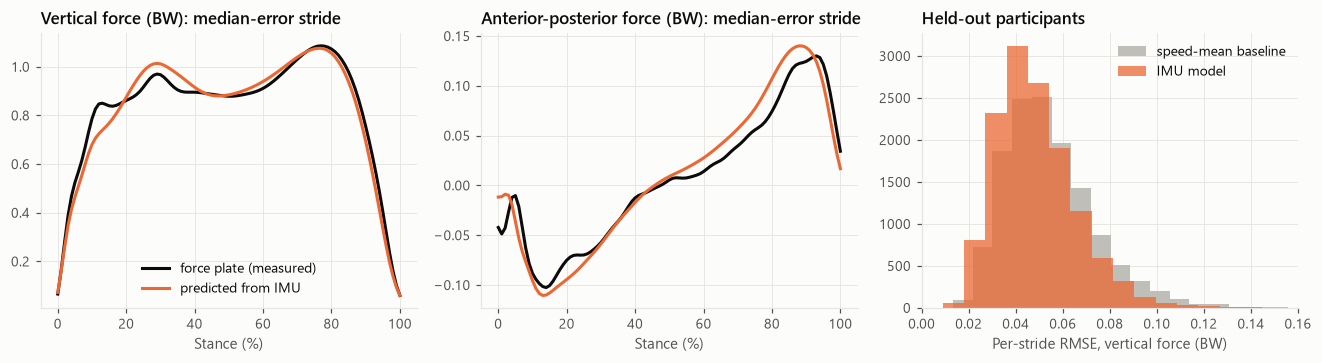

In [8]:
fp_st = pd.read_parquet(C.CACHE / "fp_strides.parquet")
fpc = dict(np.load(C.CACHE / "fp_curves.npz"))
fp_st["row"] = np.arange(len(fp_st)); imu["row"] = np.arange(len(imu))
A = fp_st[fp_st["qc_ok"]].merge(aligned, on=["subject", "speed"])
B = imu[imu["qc_ok"]].merge(aligned, on=["subject", "speed"])
pairs_ = []
for (s, v, side), a in A.groupby(["subject", "speed", "side"]):
    b = B[(B.subject == s) & (B.speed == v) & (B.side == side)]
    if b.empty:
        continue
    m = pd.merge_asof(a.sort_values("t_hs")[["t_hs", "row"]], b.sort_values("t_hs")[["t_hs", "row"]].rename(columns={"t_hs": "t_imu", "row": "row_imu"}),
                      left_on="t_hs", right_on="t_imu", direction="nearest", tolerance=0.1)
    pairs_.append(m.dropna().assign(subject=s, speed=v))
PR = pd.concat(pairs_).reset_index(drop=True)
ri, rf = PR["row_imu"].astype(int).to_numpy(), PR["row"].astype(int).to_numpy()
Xs = np.hstack([ic[k][ri][:, ::2] for k in ("hip_flex", "knee_flex", "ankle_dorsi", "hip_abd")] +
               [imu.loc[ri, ["stride_time", "stance_pct"]].to_numpy()])
print(f"Matched strides: {len(PR)} from {PR.groupby(['subject', 'speed']).ngroups} trials, {PR.subject.nunique()} participants")

from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
g = PR["subject"].to_numpy()
wave = {}
for comp in ("Fz", "Fy"):
    Y = fpc[comp][rf]
    pred, base = np.zeros_like(Y), np.zeros_like(Y)
    for tr_i, te_i in GroupKFold(10).split(Xs, Y, g):
        mdl = make_pipeline(StandardScaler(), Ridge(alpha=10.0)).fit(Xs[tr_i], Y[tr_i])
        pred[te_i] = mdl.predict(Xs[te_i])
        for s in C.SPEEDS:
            tr_s, te_s = tr_i[PR["speed"].to_numpy()[tr_i] == s], te_i[PR["speed"].to_numpy()[te_i] == s]
            base[te_s] = Y[tr_s].mean(0)
    rmse_m = np.sqrt(((pred - Y) ** 2).mean(1)); rmse_b = np.sqrt(((base - Y) ** 2).mean(1))
    rr = np.array([np.corrcoef(p, y)[0, 1] for p, y in zip(pred, Y)])
    wave[comp] = {"rmse_model": rmse_m, "rmse_base": rmse_b, "r": rr, "pred": pred, "Y": Y}
    print(f"{comp}: RMSE {np.median(rmse_m):.3f} BW (speed-mean baseline {np.median(rmse_b):.3f} BW), "
          f"error reduction {100 * (1 - np.median(rmse_m) / np.median(rmse_b)):.0f} %, median waveform r = {np.median(rr):.3f}")
pd.DataFrame({comp: {"median RMSE model (BW)": np.median(w["rmse_model"]), "median RMSE speed-mean baseline (BW)": np.median(w["rmse_base"]),
                     "median waveform r": np.median(w["r"]), "strides": len(w["r"])} for comp, w in wave.items()}).T.to_csv(C.TABLES / "virtual_force_plate_stride.csv")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
rng = np.random.default_rng(3)
for ax, comp, lab in zip(axes[:2], ("Fz", "Fy"), ("Vertical force (BW)", "Anterior-posterior force (BW)")):
    w = wave[comp]
    i = int(np.argsort(w["rmse_model"])[len(w["rmse_model"]) // 2])  # a median-error stride
    ax.plot(x, w["Y"][i], color=P.INK, label="force plate (measured)")
    ax.plot(x, w["pred"][i], color=P.CAT[1], label="predicted from IMU")
    ax.set_title(f"{lab}: median-error stride"); ax.set_xlabel("Stance (%)")
axes[0].legend(loc="lower center")
axes[2].hist(wave["Fz"]["rmse_base"], bins=40, color=P.NEUTRAL, alpha=0.9, label="speed-mean baseline")
axes[2].hist(wave["Fz"]["rmse_model"], bins=40, color=P.CAT[1], alpha=0.75, label="IMU model")
axes[2].set_xlabel("Per-stride RMSE, vertical force (BW)"); axes[2].set_title("Held-out participants"); axes[2].set_xlim(0, 0.16)
axes[2].legend()
fig.tight_layout()
P.save(fig, "03_virtual_force_plate")
plt.show()

## 7. Summary

Results are on held-out participants only (45 participants, 129 aligned trials for timing; 58 participants
for force prediction).

| Level | Result | Verdict |
|---|---|---|
| Gait events | 99 % detected; mean bias -18 ms (heel strike), -26 ms (toe-off); within-trial jitter 25-28 ms | Usable for stride segmentation |
| Stride time | ICC 0.999, 95 % limits +/-12 ms | Interchangeable with force plates |
| Stance % | ICC 0.77, 95 % limits about +/-4 percentage points | Good for group trends, not for individual thresholds |
| Stride variability | ICC 0.89 | Usable with caution (frame jitter inflates it) |
| Walking speed | MAE 0.032 m/s (4.3 %); 92 % of trials within 10 % | Usable without a treadmill |
| Trial-level loading | R2 0.85-0.92 for stance, double support, braking and propulsion; 0.70 for loading rate | Virtual force plate is feasible for summary metrics |
| First vertical peak, medial force | R2 below 0.2 | Not recoverable from kinematics |
| Stride-level waveforms | Waveform r = 0.99 but only 6-10 % lower error than a speed-matched template | Waveform detail is not recovered |

The IMU suit can replace the treadmill for timing, speed and the main loading summaries. It cannot replace
it where the clinical question depends on a person's individual force waveform or on the impact peak:
most of the waveform shape is explained by walking speed, and the kinematics add little individual
information beyond it. That boundary is the main decision input from this notebook.